In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/bcaffo/ds4bme_intro/master/data/kirby21.csv")
df=df.drop(['Unnamed: 0','rawid', 'min', 'max', 'mean', 'std'], axis=1)
df.head(4)

,roi,volume,type,level,id,icv,tbv
0,Telencephalon_L,531111,1,1,127,1378295,1268519
1,Telencephalon_R,543404,1,1,127,1378295,1268519
2,Diencephalon_L,9683,1,1,127,1378295,1268519
3,Diencephalon_R,9678,1,1,127,1378295,1268519


In [3]:
t1l1=df.loc[(df.type==1)&(df.level==1)]
t1l1=t1l1.assign(comp=t1l1.volume/t1l1.tbv)
t1l1=t1l1.loc[t1l1.roi != 'CSF']
summary=t1l1[['roi','comp']].groupby('roi', as_index=False).mean()
print(summary)

               roi      comp
0   Diencephalon_L  0.007563
1   Diencephalon_R  0.007634
2    Mesencephalon  0.008647
3    Metencephalon  0.124883
4   Myelencephalon  0.003785
5  Telencephalon_L  0.420305
6  Telencephalon_R  0.427184


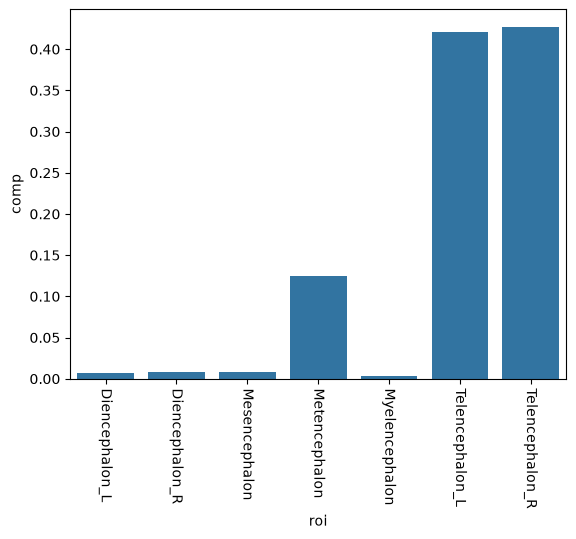

In [ ]:
g=sns.barplot(x='roi',y='comp', data=summary);
plt.xticks(rotation=-90); #rotate x-axis label 

In [6]:
t1l1pivot=t1l1.pivot(index='id', columns='roi', values='volume')
t1l1pivot.head(4)

roi,Diencephalon_L,Diencephalon_R,Mesencephalon,Metencephalon,Myelencephalon,Telencephalon_L,Telencephalon_R
id,,,,,,,
127,9683,9678,10268,159402,4973,531111,543404
142,9156,9071,10516,165803,4912,545603,552216
239,8937,9004,9070,124504,4023,483107,490805
346,8828,8933,9788,135090,4428,558849,568830


In [7]:
t1l1pivot=t1l1.pivot(index='id', columns='roi', values='volume')
t1l1pivot.head(4)

roi,Diencephalon_L,Diencephalon_R,Mesencephalon,Metencephalon,Myelencephalon,Telencephalon_L,Telencephalon_R
id,,,,,,,
127,9683,9678,10268,159402,4973,531111,543404
142,9156,9071,10516,165803,4912,545603,552216
239,8937,9004,9070,124504,4023,483107,490805
346,8828,8933,9788,135090,4428,558849,568830


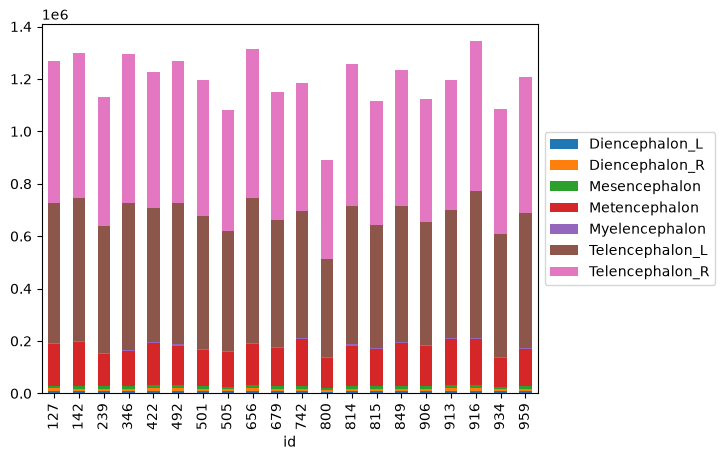

In [9]:
t1l1pivot.plot(kind='bar', stacked=True, legend=False)
plt.legend(loc='center left', bbox_to_anchor=(1.0,0.5))

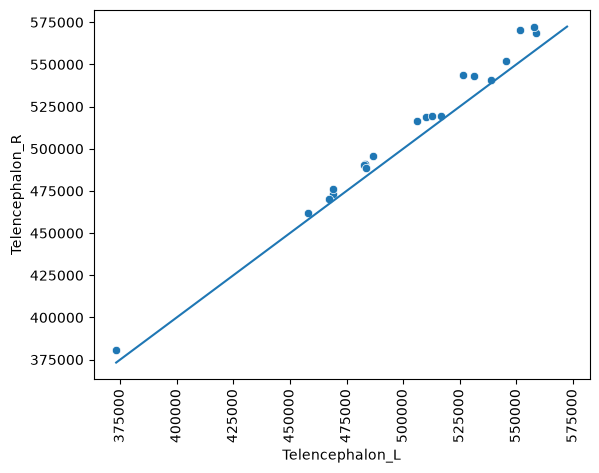

In [10]:
sns.scatterplot(x='Telencephalon_L', y="Telencephalon_R", data=t1l1pivot)
plt.xticks(rotation=90)
x1=min([t1l1pivot.Telencephalon_L.min(), t1l1pivot.Telencephalon_R.min()])
x2=max([t1l1pivot.Telencephalon_L.max(), t1l1pivot.Telencephalon_R.max()])
plt.plot([x1,x2],[x1,x2])

(array([12.8 , 12.85, 12.9 , 12.95, 13.  , 13.05, 13.1 , 13.15, 13.2 ,
        13.25, 13.3 ]),
 [Text(12.8, 0, '12.80'),
  Text(12.850000000000001, 0, '12.85'),
  Text(12.9, 0, '12.90'),
  Text(12.950000000000001, 0, '12.95'),
  Text(13.0, 0, '13.00'),
  Text(13.05, 0, '13.05'),
  Text(13.100000000000001, 0, '13.10'),
  Text(13.15, 0, '13.15'),
  Text(13.200000000000001, 0, '13.20'),
  Text(13.25, 0, '13.25'),
  Text(13.3, 0, '13.30')])

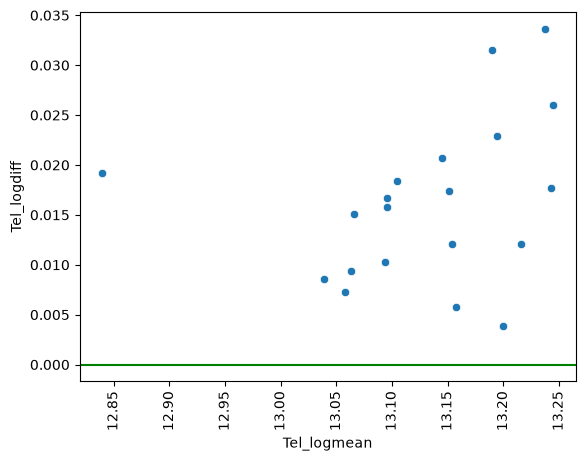

In [ ]:
t1l1pivot=t1l1pivot.assign(Tel_logmean=lambda x: (np.log(x.Telencephalon_L)*0.5 + np.log(x.Telencephalon_R)*0.5))
t1l1pivot=t1l1pivot.assign(Tel_logdiff=lambda x: (np.log(x.Telencephalon_R)-np.log(x.Telencephalon_L)))
sns.scatterplot(x="Tel_logmean", y="Tel_logdiff", data=t1l1pivot)
plt.axhline(0,color='green')
plt.xticks(rotation=90)